# Projet ML - Diabetes 130-US Hospitals

Ce notebook analyse le dataset **Diabetes 130-US Hospitals for Years 1999-2008**. Il couvre la compréhension métier, l'exploration, le nettoyage, la segmentation et la classification.

Objectifs : (1) décrire les profils de séjours, (2) segmenter les usages hospitaliers, (3) prédire une réadmission sous 30 jours (`readmitted == '<30'`).

## 1. Business Understanding

Les réadmissions hospitalières sont coûteuses et peuvent signaler un besoin de suivi renforcé. Nous étudions deux questions :

- **Classification** : identifier les séjours associés à une réadmission sous 30 jours.
- **Segmentation** : trouver des profils de séjours selon la durée, les actes, les médicaments et les recours antérieurs.

Le dataset est observationnel : les résultats décrivent des associations, pas des relations causales. La classe `<30` est minoritaire, donc l'accuracy seule serait insuffisante.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve, roc_auc_score,
    RocCurveDisplay, silhouette_score)
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, cross_val_predict,
    cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_DIR = Path('.')
# `?` est le vrai code de valeur manquante. Le texte `None` est conservé :
# dans max_glu_serum et A1Cresult, il signifie que le test n'a pas été réalisé.
df = pd.read_csv(DATA_DIR / 'diabetic_data.csv', na_values=['?'], keep_default_na=False, low_memory=False)
print(f'Dimensions : {df.shape[0]:,} lignes x {df.shape[1]} colonnes')
display(df.head(3))
ids_mapping = pd.read_csv(DATA_DIR / 'IDS_mapping.csv')
display(ids_mapping.head())

Dimensions : 101,766 lignes x 50 colonnes


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available


## 2. Data Understanding

Le dictionnaire `IDS_mapping.csv` documente les identifiants administratifs. Ils ne sont pas continus ni ordonnés comme des mesures : ils seront donc traités comme des variables catégorielles, et non standardisés comme des nombres.

Le dataset contient un séjour par ligne, mais plusieurs lignes peuvent appartenir au même patient. Cette dépendance sera prise en compte lors de la séparation entraînement/test et de la validation croisée.

In [18]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_pct': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(dropna=True),
}).sort_values('missing_pct', ascending=False)
display(summary)
print('Doublons exacts :', df.duplicated().sum())
print('Patients uniques :', df['patient_nbr'].nunique())
print('Séjours par patient :')
display(df['patient_nbr'].value_counts().describe().to_frame('value'))
print('Valeurs potentiellement invalides de gender :')
display(df['gender'].value_counts(dropna=False).to_frame('count'))
print('Cible :')
display(df['readmitted'].value_counts(dropna=False).rename_axis('readmitted').to_frame('count').assign(pct=lambda x: (x['count'] / len(df) * 100).round(2)))
print('Tests non réalisés, conservés comme catégorie explicite :')
print('max_glu_serum = None :', (df['max_glu_serum'] == 'None').sum())
print('A1Cresult = None :', (df['A1Cresult'] == 'None').sum())

,dtype,missing,missing_pct,n_unique
weight,str,98569,96.86,9
medical_specialty,str,49949,49.08,72
payer_code,str,40256,39.56,17
race,str,2273,2.23,5
diag_3,str,1423,1.40,789
diag_2,str,358,0.35,748
diag_1,str,21,0.02,716
admission_type_id,int64,0,0.00,8
patient_nbr,int64,0,0.00,71518
encounter_id,int64,0,0.00,101766


Doublons exacts : 0
Patients uniques : 71518
Séjours par patient :


,value
count,71518.000000
mean,1.422942
std,1.090740
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,40.000000


Valeurs potentiellement invalides de gender :


,count
gender,
Female,54708
Male,47055
Unknown/Invalid,3


Cible :


,count,pct
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


Tests non réalisés, conservés comme catégorie explicite :
max_glu_serum = None : 96420
A1Cresult = None : 84748


## 3. Data Exploration

Les graphiques combinent distributions marginales, comparaison avec la cible et détection visuelle des valeurs atypiques. `Unknown/Invalid` dans `gender` est un état de qualité documenté, pas une valeur à remplacer arbitrairement par le mode.

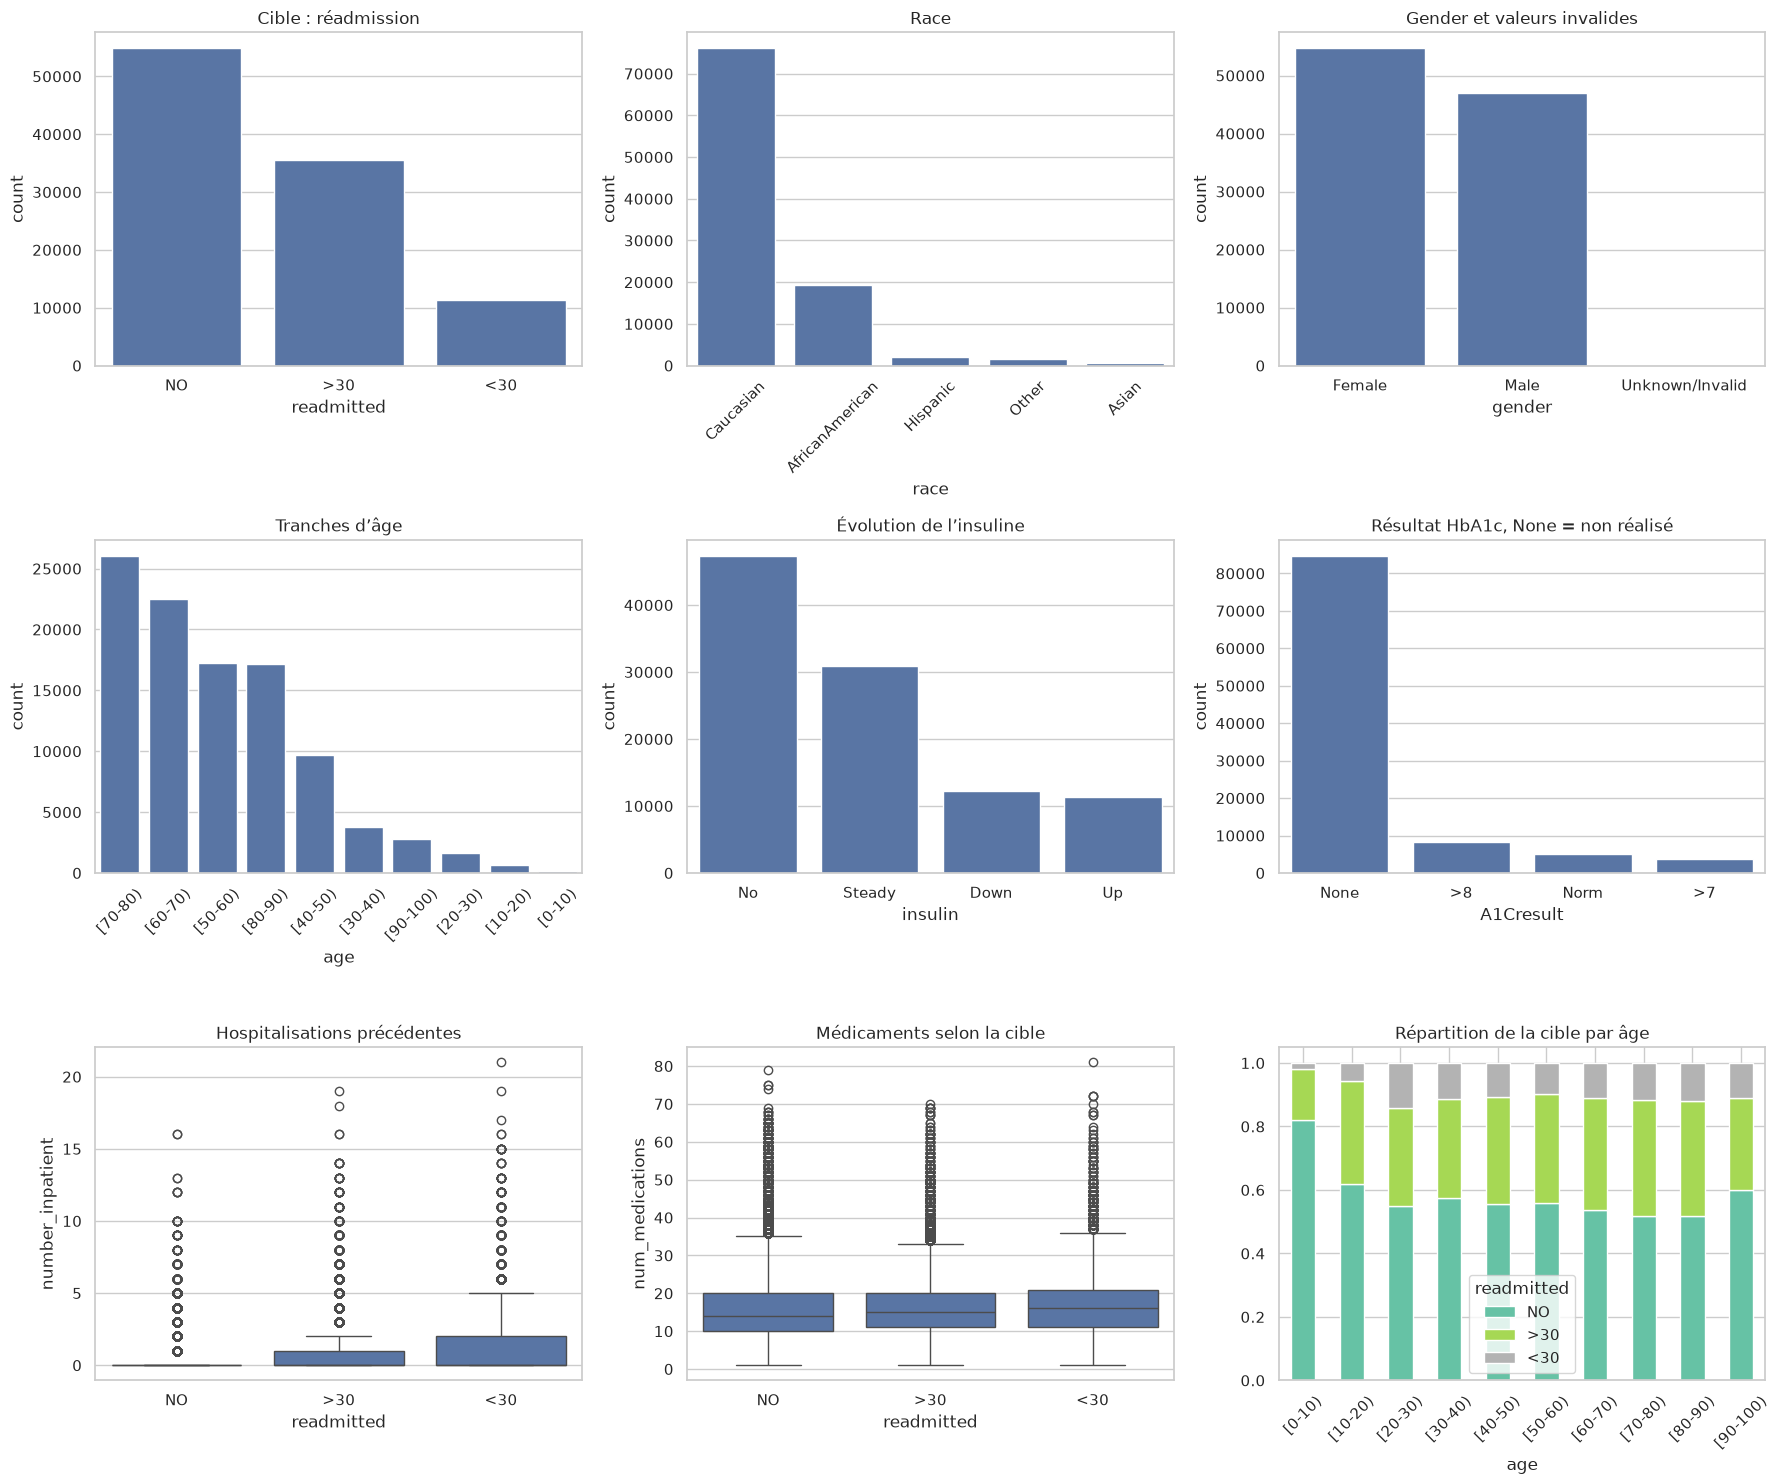

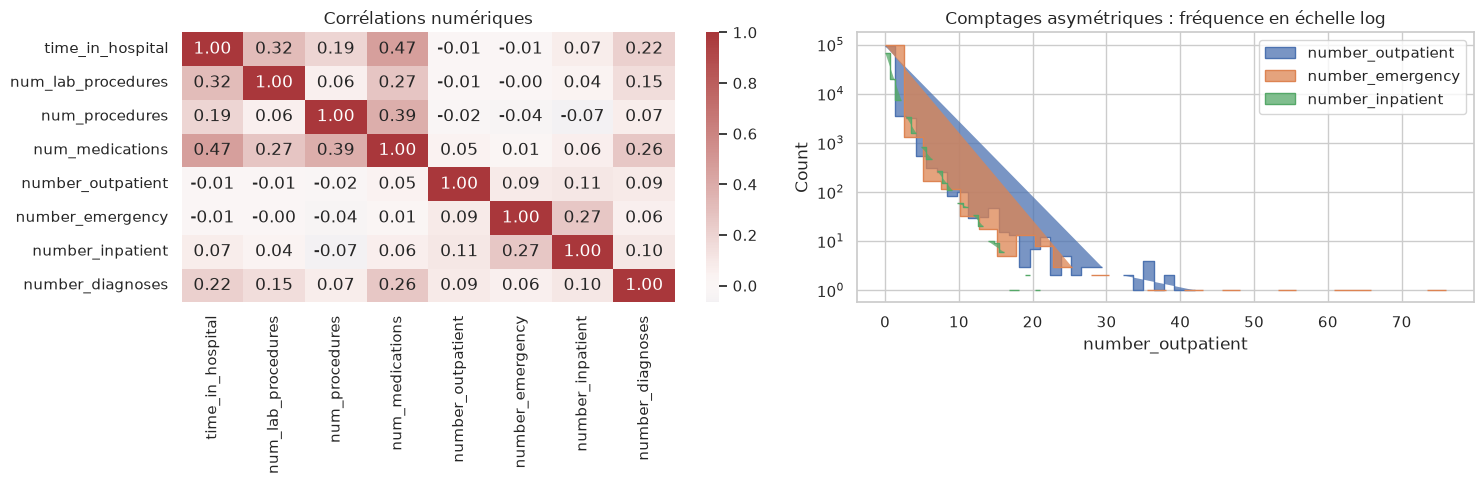

In [19]:
sns.set_theme(style='whitegrid', palette='deep')
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'], ax=axes[0, 0])
axes[0, 0].set_title('Cible : réadmission')
sns.countplot(data=df, x='race', order=df['race'].value_counts().index, ax=axes[0, 1])
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].set_title('Race')
sns.countplot(data=df, x='gender', ax=axes[0, 2])
axes[0, 2].set_title('Gender et valeurs invalides')
sns.countplot(data=df, x='age', order=df['age'].value_counts().index, ax=axes[1, 0])
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_title('Tranches d’âge')
sns.countplot(data=df, x='insulin', order=df['insulin'].value_counts().index, ax=axes[1, 1])
axes[1, 1].set_title('Évolution de l’insuline')
sns.countplot(data=df, x='A1Cresult', order=df['A1Cresult'].value_counts().index, ax=axes[1, 2])
axes[1, 2].set_title('Résultat HbA1c, None = non réalisé')
sns.boxplot(data=df, x='readmitted', y='number_inpatient', order=['NO', '>30', '<30'], ax=axes[2, 0])
axes[2, 0].set_title('Hospitalisations précédentes')
sns.boxplot(data=df, x='readmitted', y='num_medications', order=['NO', '>30', '<30'], ax=axes[2, 1])
axes[2, 1].set_title('Médicaments selon la cible')
target_by_age = pd.crosstab(df['age'], df['readmitted'], normalize='index').reindex(columns=['NO', '>30', '<30'])
target_by_age.plot(kind='bar', stacked=True, ax=axes[2, 2], colormap='Set2')
axes[2, 2].set_title('Répartition de la cible par âge')
axes[2, 2].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
numeric_for_corr = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df[numeric_for_corr].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0])
axes[0].set_title('Corrélations numériques')
for column in ['number_outpatient', 'number_emergency', 'number_inpatient']:
    sns.histplot(data=df, x=column, bins=30, log_scale=(False, True), ax=axes[1], label=column, element='step')
axes[1].set_title('Comptages asymétriques : fréquence en échelle log')
axes[1].legend(); plt.tight_layout(); plt.show()

In [20]:
outlier_rows = []
for column in numeric_for_corr:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        'variable': column,
        'skewness': values.skew(),
        'q1': q1, 'q3': q3, 'lower_IQR': lower, 'upper_IQR': upper,
        'outlier_pct': ((values < lower) | (values > upper)).mean() * 100,
    })
outlier_report = pd.DataFrame(outlier_rows).set_index('variable').round(3)
display(outlier_report)

# La transformation log1p sera appliquée aux comptages positifs et son effet est mesuré.
skewness_before_after = pd.DataFrame({
    'before': [df[c].skew() for c in ['number_outpatient', 'number_emergency', 'number_inpatient']],
    'after_log1p': [np.log1p(df[c]).skew() for c in ['number_outpatient', 'number_emergency', 'number_inpatient']],
}, index=['number_outpatient', 'number_emergency', 'number_inpatient']).round(3)
display(skewness_before_after)

,skewness,q1,q3,lower_IQR,upper_IQR,outlier_pct
variable,,,,,,
time_in_hospital,1.134,2.0,6.0,-4.0,12.0,2.213
num_lab_procedures,-0.237,31.0,57.0,-8.0,96.0,0.141
num_procedures,1.316,0.0,2.0,-3.0,5.0,4.868
num_medications,1.327,10.0,20.0,-5.0,35.0,2.513
number_outpatient,8.833,0.0,0.0,0.0,0.0,16.449
number_emergency,22.856,0.0,0.0,0.0,0.0,11.185
number_inpatient,3.614,0.0,1.0,-1.5,2.5,6.927
number_diagnoses,-0.877,6.0,9.0,1.5,13.5,0.276


,before,after_log1p
number_outpatient,8.833,2.740
number_emergency,22.856,3.654
number_inpatient,3.614,1.442


## 4. Data Preparation : décisions justifiées

- `weight` est supprimé : environ 97 % de valeurs manquantes rendent une imputation peu crédible et créeraient une variable principalement artificielle.
- `max_glu_serum` et `A1Cresult` conservent `None` comme modalité « test non réalisé » : ce n’est pas une absence aléatoire et le remplacer par le mode effacerait une information de prise en charge.
- `payer_code` et `medical_specialty` utilisent `Unknown` : avec 40–50 % de manque, supprimer les lignes serait coûteux et le mode inventerait un payeur/spécialité.
- Les identifiants administratifs sont convertis en chaînes : leurs numéros sont des codes, pas des quantités continues.
- Les séjours avec décès ou sortie en hospice sont retirés de la classification : une réadmission ultérieure est impossible ou n’est pas comparable. Cette règle est documentée et le nombre de lignes retirées est affiché.
- Les colonnes constantes `examide` et `citoglipton` sont supprimées car elles n’apportent aucune information discriminante.
- L’âge devient une variable ordinale (`age_ordinal`) : l’ordre des tranches est informatif, contrairement à un one-hot qui traite `[0-10)` et `[90-100)` comme également éloignées.
- Les comptages sont transformés par `log1p` pour réduire l’influence des longues queues, sans supprimer les grands séjours qui peuvent être réels.
- Les diagnostics deviennent des familles ICD, et le feature engineering ajoute les visites antérieures, le nombre de traitements modifiés et le nombre de médicaments prescrits.

In [21]:
def icd_group(value):
    if pd.isna(value) or value == '':
        return 'Missing'
    try:
        number = float(str(value).strip())
    except ValueError:
        return 'Other'
    if 390 <= number <= 459 or number == 785: return 'Circulatory'
    if 460 <= number <= 519 or number == 786: return 'Respiratory'
    if 520 <= number <= 579 or number == 787: return 'Digestive'
    if 250 <= number < 251: return 'Diabetes'
    if 580 <= number <= 629 or number == 788: return 'Genitourinary'
    if 800 <= number <= 999: return 'Injury'
    if 140 <= number <= 239: return 'Neoplasms'
    if 710 <= number <= 739: return 'Musculoskeletal'
    if 1 <= number <= 139: return 'Infectious'
    return 'Other'

# 1) Retirer les issues qui ne peuvent pas avoir une réadmission comparable.
non_readmittable_dispositions = {'11', '13', '14', '19', '20', '21'}
work = df.copy()
work['discharge_disposition_id'] = work['discharge_disposition_id'].astype(str)
removed = work['discharge_disposition_id'].isin(non_readmittable_dispositions).sum()
work = work.loc[~work['discharge_disposition_id'].isin(non_readmittable_dispositions)].copy()
print(f'Séjours décès/hospice retirés : {removed:,}')

# 2) Construire les variables métier avant de supprimer les identifiants.
work['target_30d'] = (work['readmitted'] == '<30').astype(int)
work['age_ordinal'] = work['age'].map({f'[{10 * i}-{10 * (i + 1)})': i for i in range(10)}).fillna(-1)
for column in ['diag_1', 'diag_2', 'diag_3']:
    work[f'{column}_group'] = work[column].map(icd_group)
work['total_prior_visits'] = work['number_outpatient'] + work['number_emergency'] + work['number_inpatient']
drug_columns = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
work['medication_changes'] = work[drug_columns].isin(['Up', 'Down', 'Ch']).sum(axis=1)
work['active_medication_count'] = work[drug_columns].isin(['Up', 'Down', 'Steady']).sum(axis=1)

# 3) Supprimer les colonnes non exploitables ou constantes.
constant_columns = [column for column in work.columns if work[column].nunique(dropna=False) <= 1]
print('Colonnes constantes supprimées :', constant_columns)
work = work.drop(columns=constant_columns + ['weight', 'diag_1', 'diag_2', 'diag_3'])

# 4) Les codes administratifs sont catégoriels ; les catégories manquantes sont explicites.
code_columns = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
for column in code_columns + ['payer_code', 'medical_specialty', 'race', 'gender', 'age', 'max_glu_serum', 'A1Cresult'] + [c for c in work.columns if c.endswith('_group')]:
    work[column] = work[column].astype('string').fillna('Unknown').replace({'': 'Unknown'})

# `Unknown/Invalid` est conservé : le remplacer par le mode supposerait une erreur de saisie.
work['gender'] = work['gender'].replace({'Unknown/Invalid': 'Unknown'})

# 5) Imputation numérique déterministe et transformation des comptages.
numeric_columns = work.select_dtypes(include=np.number).columns.tolist()
numeric_predictors = [c for c in numeric_columns if c not in ['target_30d', 'patient_nbr', 'encounter_id']]
for column in numeric_predictors:
    work[column] = work[column].fillna(work[column].median())
for column in ['number_outpatient', 'number_emergency', 'number_inpatient', 'total_prior_visits']:
    work[column] = np.log1p(work[column])

# Le groupe est utilisé uniquement pour le split, jamais comme prédicteur.
groups = work['patient_nbr'].copy()
model_df = work.drop(columns=['encounter_id', 'patient_nbr', 'readmitted'])
print('NaN après nettoyage :', int(model_df.isna().sum().sum()))
print(f'Dimensions nettoyées : {model_df.shape[0]:,} x {model_df.shape[1]}')
display(model_df.head())

Séjours décès/hospice retirés : 2,423
Colonnes constantes supprimées : ['examide', 'citoglipton']
NaN après nettoyage : 0
Dimensions nettoyées : 99,343 x 49


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,...,change,diabetesMed,target_30d,age_ordinal,diag_1_group,diag_2_group,diag_3_group,total_prior_visits,medication_changes,active_medication_count
0,Caucasian,Female,[0-10),6,25,1,1,Unknown,Pediatrics-Endocrinology,41,...,No,No,0,0,Diabetes,Missing,Missing,0.000000,0,0
1,Caucasian,Female,[10-20),1,1,7,3,Unknown,Unknown,59,...,Ch,Yes,0,1,Other,Diabetes,Other,0.000000,1,1
2,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,Unknown,11,...,No,Yes,0,2,Other,Diabetes,Other,1.386294,0,1
3,Caucasian,Male,[30-40),1,1,7,2,Unknown,Unknown,44,...,Ch,Yes,0,3,Infectious,Diabetes,Circulatory,0.000000,1,1
4,Caucasian,Male,[40-50),1,1,7,1,Unknown,Unknown,51,...,Ch,Yes,0,4,Neoplasms,Neoplasms,Diabetes,0.000000,0,2


## 5. Segmentation

La segmentation est descriptive : elle ne doit pas utiliser `target_30d`, `readmitted` ou les identifiants. Nous utilisons les variables numériques de complexité et de recours aux soins, ainsi que les variables dérivées. K-Means est comparé à MiniBatchKMeans ; le score de silhouette et la lisibilité des profils guident le choix final.

,KMeans,MiniBatchKMeans
2,0.2106,0.1720
3,0.1469,0.1850
4,0.0997,0.1357
5,0.1115,0.1097
6,0.1192,0.0941
7,0.1229,0.0970


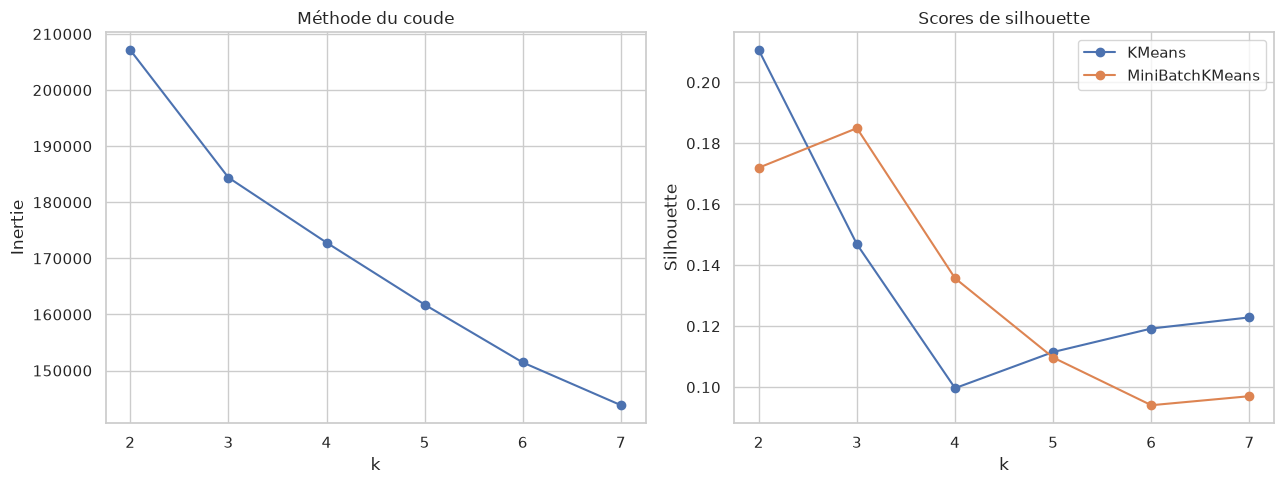

K-Means retenu : k=2, silhouette=0.2106


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,total_prior_visits,medication_changes,active_medication_count,age_ordinal,share_pct
cluster,,,,,,,,,,,,,
0,4.3,42.66,1.41,15.64,0.04,0.02,0.12,7.23,0.18,0.27,1.19,6.07,74.72
1,4.6,43.63,1.11,16.98,0.58,0.33,0.91,7.90,1.49,0.35,1.17,6.08,25.28


Lecture attendue : un cluster avec davantage de visites antérieures correspond à des utilisateurs fréquents ; un cluster avec une durée, des examens et des médicaments élevés correspond à des séjours longs et complexes ; les valeurs faibles décrivent des séjours courts et peu consommateurs.


In [22]:
cluster_features = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'total_prior_visits', 'medication_changes', 'active_medication_count', 'age_ordinal']
cluster_data = StandardScaler().fit_transform(model_df[cluster_features])
rng = np.random.RandomState(RANDOM_STATE)
sample_indices = rng.choice(len(cluster_data), size=min(20000, len(cluster_data)), replace=False)
cluster_sample = cluster_data[sample_indices]

k_values = range(2, 8)
inertias, silhouettes, minibatch_silhouettes = [], [], []
kmeans_models, minibatch_models = {}, {}
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans_labels = kmeans.fit_predict(cluster_sample)
    minibatch = MiniBatchKMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, batch_size=2048)
    minibatch_labels = minibatch.fit_predict(cluster_sample)
    kmeans_models[k], minibatch_models[k] = kmeans, minibatch
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(cluster_sample, kmeans_labels))
    minibatch_silhouettes.append(silhouette_score(cluster_sample, minibatch_labels))

comparison = pd.DataFrame({'KMeans': silhouettes, 'MiniBatchKMeans': minibatch_silhouettes}, index=list(k_values))
display(comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set(title='Méthode du coude', xlabel='k', ylabel='Inertie')
comparison.plot(marker='o', ax=axes[1])
axes[1].set(title='Scores de silhouette', xlabel='k', ylabel='Silhouette')
plt.tight_layout(); plt.show()

best_k = int(comparison['KMeans'].idxmax())
cluster_model = kmeans_models[best_k]
model_df['cluster'] = cluster_model.predict(cluster_data)
print(f'K-Means retenu : k={best_k}, silhouette={comparison.loc[best_k, "KMeans"]:.4f}')
cluster_profile = model_df.groupby('cluster')[cluster_features].mean().round(2)
cluster_profile['share_pct'] = model_df['cluster'].value_counts(normalize=True).mul(100).round(2)
display(cluster_profile.sort_index())
print('Lecture attendue : un cluster avec davantage de visites antérieures correspond à des utilisateurs fréquents ; un cluster avec une durée, des examens et des médicaments élevés correspond à des séjours longs et complexes ; les valeurs faibles décrivent des séjours courts et peu consommateurs.')

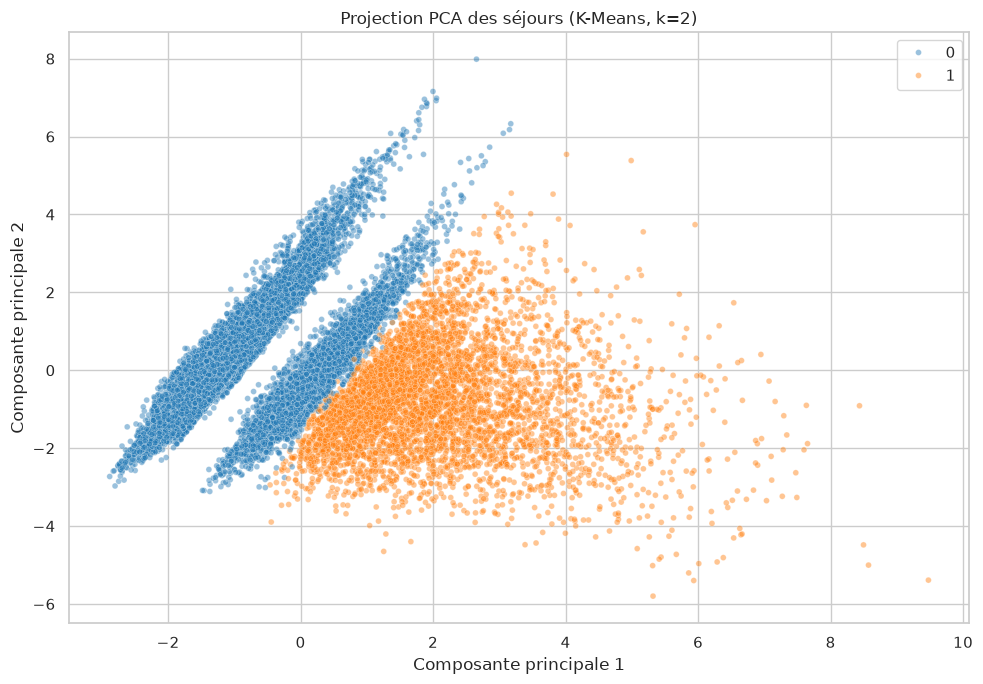

,Pas de réadmission <30j,Réadmission <30j
cluster,,
0,90.76,9.24
1,82.25,17.75


In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(cluster_sample)
sample_labels = cluster_model.predict(cluster_sample)
plt.figure(figsize=(10, 7))
sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=sample_labels, palette='tab10', s=18, alpha=0.45)
plt.title(f'Projection PCA des séjours (K-Means, k={best_k})')
plt.xlabel('Composante principale 1'); plt.ylabel('Composante principale 2')
plt.tight_layout(); plt.show()
cluster_readmission = pd.crosstab(model_df['cluster'], model_df['target_30d'], normalize='index').mul(100).round(2)
cluster_readmission.columns = ['Pas de réadmission <30j', 'Réadmission <30j']
display(cluster_readmission)

## 6. Classification

La cible est prédite après un split par patient : aucun patient ne se retrouve à la fois dans train et test. Deux modèles sont comparés : une régression logistique, baseline interprétable, et une forêt aléatoire, capable de modéliser des interactions non linéaires.

La validation croisée utilise `GroupKFold` pour conserver la contrainte patient. Les scores principaux sont ROC-AUC et Average Precision ; F1 complète l’analyse de la classe minoritaire.

In [24]:
feature_df = model_df.drop(columns=['target_30d', 'cluster', 'age'])
y = model_df['target_30d'].astype(int)

# GroupShuffleSplit sépare les patients, contrairement à un split de lignes.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_indices, test_indices = next(splitter.split(feature_df, y, groups=groups))
X_train, X_test = feature_df.iloc[train_indices], feature_df.iloc[test_indices]
y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
groups_train = groups.iloc[train_indices]
print(f'Patients train/test distincts : {set(groups_train).isdisjoint(set(groups.iloc[test_indices]))}')

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
numeric_transformer = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False))])
preprocessor = ColumnTransformer([('num', numeric_transformer, numeric_features), ('cat', categorical_transformer, categorical_features)])

logistic = Pipeline([('preprocessor', preprocessor), ('model', LogisticRegression(max_iter=1000, class_weight='balanced', solver='liblinear', random_state=RANDOM_STATE))])
forest = Pipeline([('preprocessor', preprocessor), ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE))])
models = {'Régression logistique': logistic, 'Forêt aléatoire': forest}

cv = GroupKFold(n_splits=3)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv, scoring=['roc_auc', 'average_precision', 'f1'], n_jobs=1)
    cv_rows.append({'model': name, 'ROC-AUC moyen': scores['test_roc_auc'].mean(), 'Average Precision moyenne': scores['test_average_precision'].mean(), 'F1 moyen': scores['test_f1'].mean()})
display(pd.DataFrame(cv_rows).set_index('model').round(4))

for model in models.values():
    model.fit(X_train, y_train)
logistic_probabilities = logistic.predict_proba(X_test)[:, 1]
forest_probabilities = forest.predict_proba(X_test)[:, 1]

oof_probabilities = cross_val_predict(logistic, X_train, y_train, groups=groups_train, cv=cv, method='predict_proba', n_jobs=1)[:, 1]
thresholds = np.linspace(0.10, 0.90, 81)
oof_f1 = [f1_score(y_train, (oof_probabilities >= threshold).astype(int)) for threshold in thresholds]
best_threshold = float(thresholds[int(np.argmax(oof_f1))])
print(f'Seuil retenu par F1 out-of-fold : {best_threshold:.2f}')

results = []
for name, probabilities in [('Régression logistique', logistic_probabilities), ('Forêt aléatoire', forest_probabilities)]:
    prediction = (probabilities >= (best_threshold if name == 'Régression logistique' else 0.5)).astype(int)
    results.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, probabilities), 'Average Precision': average_precision_score(y_test, probabilities), 'F1': f1_score(y_test, prediction)})
    print(f'\n{name}')
    print(classification_report(y_test, prediction, target_names=['Pas de réadmission <30j', 'Réadmission <30j']))
display(pd.DataFrame(results).set_index('model').round(4))

Patients train/test distincts : True


,ROC-AUC moyen,Average Precision moyenne,F1 moyen
model,,,
Régression logistique,0.6628,0.2069,0.2747
Forêt aléatoire,0.6683,0.2144,0.1965


Seuil retenu par F1 out-of-fold : 0.54

Régression logistique
                         precision    recall  f1-score   support

Pas de réadmission <30j       0.92      0.75      0.83     17586
       Réadmission <30j       0.19      0.48      0.27      2216

               accuracy                           0.72     19802
              macro avg       0.56      0.61      0.55     19802
           weighted avg       0.84      0.72      0.76     19802


Forêt aléatoire
                         precision    recall  f1-score   support

Pas de réadmission <30j       0.90      0.95      0.93     17586
       Réadmission <30j       0.30      0.17      0.21      2216

               accuracy                           0.86     19802
              macro avg       0.60      0.56      0.57     19802
           weighted avg       0.83      0.86      0.85     19802



,ROC-AUC,Average Precision,F1
model,,,
Régression logistique,0.6664,0.2147,0.2746
Forêt aléatoire,0.6704,0.2244,0.2142


## 7. Évaluation et interprétation

La courbe Precision-Recall est prioritaire avec une classe positive minoritaire. Le seuil logistique est choisi sur les prédictions out-of-fold du train afin de maximiser F1 sans utiliser le test. La forêt conserve un seuil de 0,5 pour fournir une comparaison standard.

Pour éviter de surinterpréter les modalités rares, l’interprétation logistique utilise les coefficients en valeur absolue et une fréquence minimale d’encodage. La forêt est complétée par une permutation d’importance sur le test.

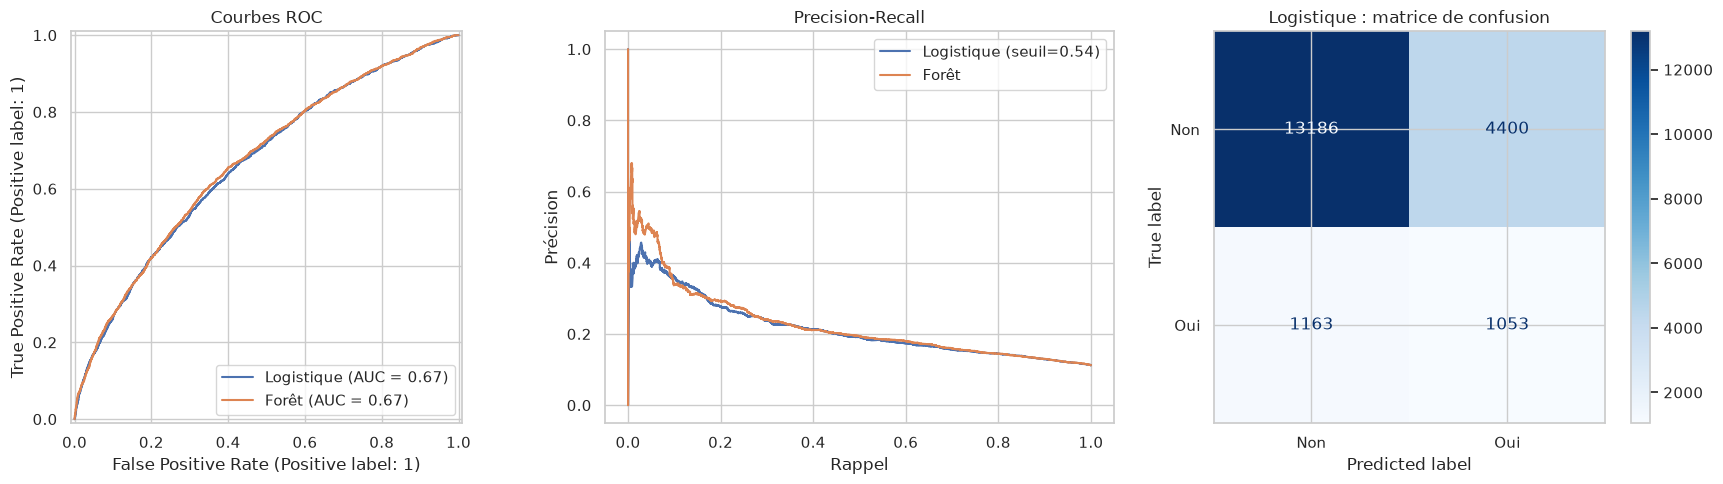

Coefficients logistiques les plus importants en valeur absolue :


,feature,coefficient,abs_coefficient
78,cat__medical_specialty_Gynecology,-1.843372,1.843372
96,cat__medical_specialty_Pediatrics-Endocrinology,-1.505869,1.505869
79,cat__medical_specialty_Hematology,1.452546,1.452546
93,cat__medical_specialty_Otolaryngology,-1.128002,1.128002
29,cat__discharge_disposition_id_15,1.116776,1.116776
33,cat__discharge_disposition_id_23,-1.088262,1.088262
71,cat__payer_code_WC,-1.070727,1.070727
36,cat__discharge_disposition_id_28,1.030484,1.030484
80,cat__medical_specialty_Hematology/Oncology,0.980818,0.980818
82,cat__medical_specialty_InfectiousDiseases,0.971454,0.971454


Importance par permutation de la forêt, au niveau des variables originales :


,feature,importance_mean
3,discharge_disposition_id,0.033920
13,number_inpatient,0.025534
44,total_prior_visits,0.011849
6,payer_code,0.004158
41,diag_1_group,0.004012
7,medical_specialty,0.004002
5,time_in_hospital,0.003837
40,age_ordinal,0.003372
12,number_emergency,0.002909
0,race,0.002713


In [25]:
logistic_predictions = (logistic_probabilities >= best_threshold).astype(int)
forest_predictions = (forest_probabilities >= 0.5).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
RocCurveDisplay.from_predictions(y_test, logistic_probabilities, name='Logistique', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, forest_probabilities, name='Forêt', ax=axes[0])
axes[0].set_title('Courbes ROC')
precision, recall, _ = precision_recall_curve(y_test, logistic_probabilities)
axes[1].plot(recall, precision, label=f'Logistique (seuil={best_threshold:.2f})')
precision_forest, recall_forest, _ = precision_recall_curve(y_test, forest_probabilities)
axes[1].plot(recall_forest, precision_forest, label='Forêt')
axes[1].set(title='Precision-Recall', xlabel='Rappel', ylabel='Précision')
axes[1].legend()
ConfusionMatrixDisplay.from_predictions(y_test, logistic_predictions, display_labels=['Non', 'Oui'], cmap='Blues', ax=axes[2])
axes[2].set_title('Logistique : matrice de confusion')
plt.tight_layout(); plt.show()

feature_names = logistic.named_steps['preprocessor'].get_feature_names_out()
coefficients = logistic.named_steps['model'].coef_[0]
importance = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients, 'abs_coefficient': np.abs(coefficients)})
print('Coefficients logistiques les plus importants en valeur absolue :')
display(importance.sort_values('abs_coefficient', ascending=False).head(15))

permutation = permutation_importance(forest, X_test, y_test, scoring='average_precision', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
permutation_table = pd.DataFrame({'feature': X_test.columns, 'importance_mean': permutation.importances_mean}).sort_values('importance_mean', ascending=False)
print('Importance par permutation de la forêt, au niveau des variables originales :')
display(permutation_table.head(15))

## 8. Export du dataset entièrement préparé et conclusion

Le livrable final doit être autonome : il ne contient plus les identifiants, `weight`, les diagnostics bruts ni `readmitted`. Les modalités sont encodées en one-hot, les variables numériques sont imputées et standardisées, les comptages ont reçu `log1p`, et `target_30d` ainsi que `cluster` sont conservés. Le fichier ne doit contenir aucune valeur manquante.

In [26]:
# Export réellement transformé : mêmes transformations que le modèle, sans IDs ni cible brute.
encoded_matrix = logistic.named_steps['preprocessor'].transform(feature_df)
encoded_names = logistic.named_steps['preprocessor'].get_feature_names_out()
encoded_df = pd.DataFrame(encoded_matrix, columns=encoded_names, index=model_df.index)
encoded_df['target_30d'] = y.to_numpy()
encoded_df['cluster'] = model_df['cluster'].to_numpy()
output_path = DATA_DIR / 'diabetic_data_prepared.csv'
encoded_df.to_csv(output_path, index=False)
print(f'Fichier exporté : {output_path.resolve()}')
print(f'Dimensions : {encoded_df.shape[0]:,} lignes x {encoded_df.shape[1]} colonnes')
print('Valeurs manquantes dans le livrable :', int(encoded_df.isna().sum().sum()))
print('Colonnes brutes interdites présentes :', set(['encounter_id', 'patient_nbr', 'weight', 'readmitted']) & set(encoded_df.columns))
print('''
Conclusion :
- Les valeurs manquantes ont été traitées selon leur signification métier : test non réalisé, Unknown ou imputation médiane.
- Les séjours décès/hospice et les colonnes constantes ont été exclus avec justification.
- Les patients ont été séparés par groupe, ce qui rend l'évaluation plus honnête que le split aléatoire de lignes.
- K-Means donne une typologie descriptive : utilisateurs fréquents, séjours complexes et séjours courts/faible recours selon les profils observés.
- La classification compare une baseline logistique à une forêt aléatoire ; ROC-AUC, Average Precision et F1 sont interprétés ensemble.
''')

Fichier exporté : /home/sphynx/Esprit/ML/P1/diabetic_data_prepared.csv
Dimensions : 99,343 lignes x 228 colonnes
Valeurs manquantes dans le livrable : 0
Colonnes brutes interdites présentes : set()

Conclusion :
- Les valeurs manquantes ont été traitées selon leur signification métier : test non réalisé, Unknown ou imputation médiane.
- Les séjours décès/hospice et les colonnes constantes ont été exclus avec justification.
- Les patients ont été séparés par groupe, ce qui rend l'évaluation plus honnête que le split aléatoire de lignes.
- K-Means donne une typologie descriptive : utilisateurs fréquents, séjours complexes et séjours courts/faible recours selon les profils observés.
- La classification compare une baseline logistique à une forêt aléatoire ; ROC-AUC, Average Precision et F1 sont interprétés ensemble.

